# Notebook 3 de 4: algoritmos y ajuste de hiperparámetros

Este notebook continúa la sesión del notebook 2. Primero medimos cuánto tarda un ajuste de cada algoritmo, para dimensionar la búsqueda. Después los
cuatro algoritmos se evalúan con sus valores por defecto (M4), después se ajustan sus hiperparámetros con tres mecanismos de búsqueda (M5) y por último se elige
el umbral de decisión de cada uno con predicciones fuera de fold (M6).

La carrera de M5 es la parte más costosa del trabajo. Sus resultados quedan guardados en `artefactos_ml/` y, si
los archivos existen, se cargan en lugar de recalcularse.

In [1]:
# Continúa la sesión del notebook 02_Planteo_y_basal (correrlo antes si el archivo no existe)
import joblib                 # se importa antes que dill para que joblib guarde los modelos con el pickle estándar
import dill
dill.load_session("artefactos_ml/estado_02.pkl")
dill.extend(False)            # deja el pickle estándar como estaba (lo usan joblib y pandas)
%matplotlib inline
print("Estado cargado desde artefactos_ml/estado_02.pkl")

Estado cargado desde artefactos_ml/estado_02.pkl


### 8.0.4 Medición de cómputo

*Esta medición forma parte de M0, pero la presentamos acá porque es donde se usa: sirve para dimensionar la búsqueda de hiperparámetros de M5.*

Antes de lanzar búsquedas pesadas se mide cuánto tarda **un ajuste** de cada algoritmo sobre un fold real
(57.000 filas de entrenamiento, 26 columnas) y se proyecta el costo de la carrera de mecanismos. Se usan
configuraciones razonables, no óptimas; el AUC en este fold solo sirve para verificar que cada algoritmo
funciona.

In [2]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score
from xgboost import XGBClassifier
from catboost import CatBoostClassifier

cv_medicion = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEMILLA)
idx_tr, idx_va = next(cv_medicion.split(Xm_train, y_train_final, groups=Xm_train["patient_nbr"]))

t0 = time.perf_counter()
prep = preprocesamiento()
Ztr = prep.fit_transform(Xm_train.iloc[idx_tr], y_train_final.iloc[idx_tr])
Zva = prep.transform(Xm_train.iloc[idx_va])
t_prep = time.perf_counter() - t0
ytr, yva = y_train_final.iloc[idx_tr], y_train_final.iloc[idx_va]

modelos_medicion = {
    "Regresión logística": LogisticRegression(C=1.0, max_iter=2000),
    "Random Forest": RandomForestClassifier(n_estimators=500, max_features="sqrt", n_jobs=-1,
                                            random_state=SEMILLA),
    "XGBoost": XGBClassifier(n_estimators=500, learning_rate=0.05, max_depth=6, tree_method="hist",
                             n_jobs=-1, random_state=SEMILLA),
    "CatBoost": CatBoostClassifier(iterations=1000, depth=6, random_seed=SEMILLA, verbose=0,
                                   thread_count=-1),
}
filas = []
for nombre, modelo in modelos_medicion.items():
    t0 = time.perf_counter()
    modelo.fit(Ztr, ytr)
    t_fit = time.perf_counter() - t0
    filas.append({"algoritmo": nombre, "segundos por ajuste": round(t_fit, 1),
                  "ROC-AUC (fold 1, verificación)": round(roc_auc_score(yva, modelo.predict_proba(Zva)[:, 1]), 3)})
medicion = pd.DataFrame(filas).set_index("algoritmo")
print(f"Preprocesamiento de un fold (ajuste + transformación): {t_prep:.1f} s | "
      f"entrenamiento: {len(idx_tr)} filas | validación: {len(idx_va)} filas")
medicion

Preprocesamiento de un fold (ajuste + transformación): 2.1 s | entrenamiento: 57266 filas | validación: 14317 filas


,segundos por ajuste,"ROC-AUC (fold 1, verificación)"
algoritmo,,
Regresión logística,0.0,0.662
Random Forest,1.8,0.650
XGBoost,1.1,0.666
CatBoost,2.8,0.670


In [3]:
# Proyección del costo de la carrera de mecanismos: evaluaciones por mecanismo x 5 folds x 3 mecanismos
EVALUACIONES = {"Regresión logística": 16, "Random Forest": 40, "XGBoost": 40, "CatBoost": 40}
FOLDS, MECANISMOS = 5, 3
proy = medicion[["segundos por ajuste"]].copy()
proy["evaluaciones por mecanismo"] = pd.Series(EVALUACIONES)
proy["ajustes en la carrera"] = proy["evaluaciones por mecanismo"] * FOLDS * MECANISMOS
proy["horas estimadas"] = (proy["segundos por ajuste"] * proy["ajustes en la carrera"] / 3600).round(2)
proy.loc["Total"] = ["", "", int(proy["ajustes en la carrera"].sum()), round(proy["horas estimadas"].sum(), 2)]
proy

,segundos por ajuste,evaluaciones por mecanismo,ajustes en la carrera,horas estimadas
algoritmo,,,,
Regresión logística,0.0,16,240,0.00
Random Forest,1.8,40,600,0.30
XGBoost,1.1,40,600,0.18
CatBoost,2.8,40,600,0.47
Total,,,2040,0.95


**Lectura.** Con 14 núcleos, un ajuste tarda entre 0 y 3 segundos, y el
preprocesamiento de un fold toma 2,1 segundos y se calcula una sola vez por fold. Con 40 evaluaciones por
mecanismo, la carrera completa de los cuatro algoritmos suma 2.040 ajustes y alrededor de una hora de
cómputo. El presupuesto definitivo se fija en M5, porque los espacios de búsqueda incluyen modelos más
grandes que estas configuraciones de prueba y cada ajuste puede tardar varias veces más.

El ROC-AUC de la columna de verificación corresponde a un solo fold con las configuraciones de prueba, y solo
comprueba que los cuatro algoritmos funcionan (entre 0,65 y 0,67). No se usa para comparar algoritmos: eso se
hace en M4 con los cinco folds y las repeticiones.

## 8.4 M4: Algoritmos candidatos con hiperparámetros por defecto

**Por qué estos cuatro algoritmos.** Elegimos candidatos de familias distintas, para que la comparación diga algo
sobre el tipo de modelo y no solo sobre una implementación en particular:

| Algoritmo | Familia | Por qué lo incluimos |
|---|---|---|
| Regresión logística | Lineal | Es la referencia interpretable: si un modelo lineal alcanza, no se justifica más complejidad. Sus coeficientes además permiten contrastar lo que encontramos en el EDA. |
| Random Forest | Ensamble en paralelo (bagging) | Captura interacciones y relaciones no lineales sin suponer una forma para las variables, y es estable con poco ajuste. |
| XGBoost | Ensamble secuencial (boosting) | Es de los algoritmos con mejor desempeño habitual en datos tabulares como estos. |
| CatBoost | Ensamble secuencial (boosting) | Otro boosting, con árboles simétricos y una regularización distinta a la de XGBoost. Tener dos boostings permite distinguir si una diferencia es propia de la familia o de la implementación. |

Primero los evaluamos con los valores por defecto de cada librería, sobre los mismos 5 folds (semilla 42) y el
mismo preprocesamiento por fold que el basal. Cada uno se evalúa dos veces, sobre el entrenamiento y sobre la
validación, porque **la brecha entre ambas es parte del resultado**: señala sobreajuste cuando la métrica de
entrenamiento es mucho mayor que la de validación.

**Por qué no KNN, SVM ni un árbol solo**, que también vimos en la materia. KNN necesita calcular la distancia de
cada paciente nuevo a los 57.000 del entrenamiento, y con variables codificadas de naturaleza tan distinta
(conteos, tasas de target encoding, dummies) la distancia pierde significado clínico. SVM con kernel no lineal
escala mal con la cantidad de observaciones y, como vimos en la clase 7, no devuelve probabilidades propias sino
distancias al hiperplano. Un árbol solo sobreajusta o, si se lo poda, pierde precisión: es justamente el problema
que resuelven Random Forest y boosting (clases 4 y 5).

No descartamos ninguna familia por su desempeño con valores por defecto: un algoritmo mal configurado puede
rendir poco y mejorar mucho al ajustar sus hiperparámetros. Lo vimos en la notebook *3 - Boosting y XGBoost* de
la clase 5, donde AdaBoost con una mala configuración "no llega ni a ajustar" y con una configuración razonable
compite con los mejores ensambles. Esa decisión se toma en M5.

En esta etapa solo se informan las métricas que no dependen de un umbral (ROC-AUC y AUC-PR). Recall,
precisión, F1 y exactitud balanceada se calculan en M6, con el umbral elegido sobre predicciones fuera de fold
para cada algoritmo ya ajustado.

In [4]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from catboost import CatBoostClassifier

_CACHE = {}


def matrices(semilla, k):
    # Preprocesamiento ajustado solo con el train del fold k; se calcula una vez y se reutiliza.
    if (semilla, k) not in _CACHE:
        tr, va = pares(semilla)[k]
        prep = preprocesamiento()
        Ztr = prep.fit_transform(Xm_train.iloc[tr], y_ent.iloc[tr])
        Zva = prep.transform(Xm_train.iloc[va])
        _CACHE[(semilla, k)] = (Ztr, Zva, y_ent.iloc[tr].to_numpy(), y_ent.iloc[va].to_numpy())
    return _CACHE[(semilla, k)]


def fabricar(nombre):
    # Valores por defecto de cada librería; solo se fijan la semilla y el paralelismo (no son hiperparámetros).
    if nombre == "Regresión logística":
        return LogisticRegression()
    if nombre == "Random Forest":
        return RandomForestClassifier(random_state=SEMILLA, n_jobs=-1)
    if nombre == "XGBoost":
        return XGBClassifier(random_state=SEMILLA, n_jobs=-1)
    if nombre == "CatBoost":
        return CatBoostClassifier(random_seed=SEMILLA, verbose=0, thread_count=-1)


ALGORITMOS = ["Regresión logística", "Random Forest", "XGBoost", "CatBoost"]

filas = []
for nombre in ALGORITMOS:
    for k in range(N_FOLDS):
        Ztr, Zva, ytr, yva = matrices(42, k)
        modelo = fabricar(nombre)
        t0 = time.perf_counter()
        modelo.fit(Ztr, ytr)
        seg = time.perf_counter() - t0
        p_tr, p_va = modelo.predict_proba(Ztr)[:, 1], modelo.predict_proba(Zva)[:, 1]
        fila = {"algoritmo": nombre, "fold": k + 1, "segundos": seg,
                "ROC-AUC entrenamiento": roc_auc_score(ytr, p_tr), "ROC-AUC validación": roc_auc_score(yva, p_va),
                "AUC-PR entrenamiento": average_precision_score(ytr, p_tr),
                "AUC-PR validación": average_precision_score(yva, p_va)}
        filas.append(fila)
        registrar(fase="M4", mecanismo="valores por defecto", semilla=42, **fila)

m4 = pd.DataFrame(filas)
auc_basal = basal_folds["ROC-AUC"].to_numpy()          # ROC-AUC del basal en los mismos 5 folds

resumen_m4 = m4.groupby("algoritmo", sort=False).agg(
    **{"ROC-AUC entrenamiento": ("ROC-AUC entrenamiento", "mean"),
       "ROC-AUC validación": ("ROC-AUC validación", "mean"),
       "desvío validación": ("ROC-AUC validación", "std"),
       "AUC-PR entrenamiento": ("AUC-PR entrenamiento", "mean"),
       "AUC-PR validación": ("AUC-PR validación", "mean"),
       "segundos por ajuste": ("segundos", "mean")})
resumen_m4["brecha ROC-AUC (entren. - valid.)"] = resumen_m4["ROC-AUC entrenamiento"] - resumen_m4["ROC-AUC validación"]

dif = {n: m4[m4["algoritmo"] == n]["ROC-AUC validación"].to_numpy() - auc_basal for n in ALGORITMOS}
resumen_m4["mejora media sobre el basal"] = [dif[n].mean() for n in resumen_m4.index]
resumen_m4["desvío de la mejora"] = [dif[n].std(ddof=1) for n in resumen_m4.index]
resumen_m4["positiva en los 5 folds"] = ["sí" if (dif[n] > 0).all() else "no" for n in resumen_m4.index]
resumen_m4["supera al basal (criterio M2)"] = ["SÍ" if (dif[n].mean() > dif[n].std(ddof=1) and (dif[n] > 0).all())
                                              else "no" for n in resumen_m4.index]
guardar_registro()
resumen_m4.round(4)

,ROC-AUC entrenamiento,ROC-AUC validación,desvío validación,AUC-PR entrenamiento,AUC-PR validación,segundos por ajuste,brecha ROC-AUC (entren. - valid.),mejora media sobre el basal,desvío de la mejora,positiva en los 5 folds,supera al basal (criterio M2)
algoritmo,,,,,,,,,,,
Regresión logística,0.6720,0.6704,0.0046,0.2048,0.2042,0.0078,0.0015,0.0643,0.0082,sí,SÍ
Random Forest,1.0000,0.6493,0.0056,1.0000,0.1972,0.3994,0.3507,0.0432,0.0091,sí,SÍ
XGBoost,0.8629,0.6574,0.0058,0.5753,0.1985,0.2448,0.2055,0.0513,0.0074,sí,SÍ
CatBoost,0.8234,0.6744,0.0028,0.5255,0.2164,2.6001,0.1490,0.0683,0.0063,sí,SÍ


**Lectura de la tabla.** Con valores por defecto, los cuatro algoritmos superan al basal (ROC-AUC 0,606) según
el criterio de M2 (notebook 2): la mejora media va de 0,043 (Random Forest) a 0,068 (CatBoost), es positiva en los cinco
folds y mayor que su desvío entre folds (entre 0,006 y 0,009). CatBoost y la regresión logística quedan
prácticamente a la par (ROC-AUC de validación 0,674 y 0,670; la diferencia es menor que el desvío entre
folds, de 0,003 a 0,005), y CatBoost tiene el AUC-PR más alto (0,216 contra 0,204). XGBoost (0,657) y Random
Forest (0,649) quedan por debajo con estos valores, pero no se descartan: sus hiperparámetros por defecto no
son los adecuados para este tamaño de datos, como muestra la brecha.

La **brecha entre entrenamiento y validación** es la señal de sobreajuste. La regresión logística casi no
sobreajusta (0,002). Random Forest memoriza el entrenamiento (ROC-AUC 1,000 contra 0,649 en validación),
porque por defecto crece árboles sin límite de profundidad. XGBoost (0,863 contra 0,657) y CatBoost (0,823
contra 0,674) sobreajustan menos, pero con una brecha grande. Los tres ensambles tienen entonces margen para
regularizar (profundidad, tasa de aprendizaje, cantidad de árboles), que es lo que busca M5. Que un modelo
lineal quede a la par del mejor ensamble sugiere que, con estas 18 variables, los modelos más complejos
encuentran poco más que lo lineal; M5 mostrará si el ajuste cambia ese panorama.

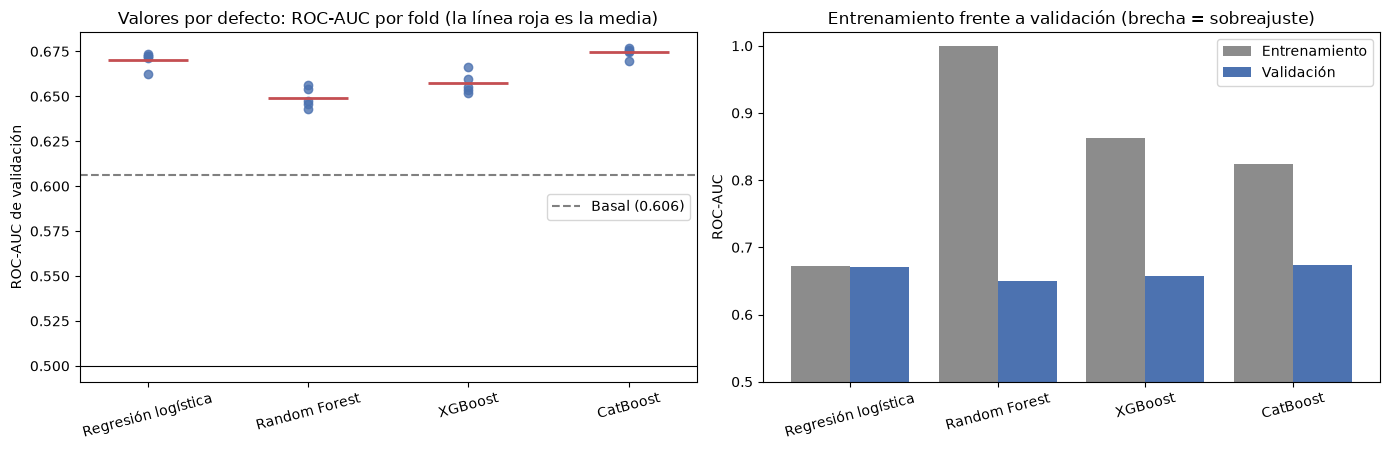

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))

# (a) ROC-AUC de validación por fold, con el basal como referencia
ax = axes[0]
for i, nombre in enumerate(ALGORITMOS):
    v = m4[m4["algoritmo"] == nombre]["ROC-AUC validación"].to_numpy()
    ax.scatter(np.full(len(v), i), v, color="#4C72B0", alpha=0.8, zorder=3)
    ax.hlines(v.mean(), i - 0.25, i + 0.25, color="#C44E52", lw=2, zorder=4)
ax.axhline(auc_basal.mean(), color="gray", ls="--", label=f"Basal ({auc_basal.mean():.3f})")
ax.axhline(0.5, color="black", lw=0.8)
ax.set_xticks(range(len(ALGORITMOS)))
ax.set_xticklabels(ALGORITMOS, rotation=15)
ax.set_ylabel("ROC-AUC de validación")
ax.set_title("Valores por defecto: ROC-AUC por fold (la línea roja es la media)")
ax.legend()

# (b) entrenamiento frente a validación
ax = axes[1]
x = np.arange(len(ALGORITMOS))
ax.bar(x - 0.2, resumen_m4["ROC-AUC entrenamiento"], 0.4, label="Entrenamiento", color="#8C8C8C")
ax.bar(x + 0.2, resumen_m4["ROC-AUC validación"], 0.4, label="Validación", color="#4C72B0")
ax.set_xticks(x)
ax.set_xticklabels(ALGORITMOS, rotation=15)
ax.set_ylim(0.5, 1.02)
ax.set_ylabel("ROC-AUC")
ax.set_title("Entrenamiento frente a validación (brecha = sobreajuste)")
ax.legend()
plt.tight_layout()
plt.show()

**Lectura del gráfico.** En el panel izquierdo, la dispersión entre folds de cada algoritmo (unos 0,01 de
punta a punta) es menor que la distancia que los separa del basal: todos los puntos quedan por encima de la
línea del basal y los cuatro algoritmos se separan del piso de 0,5. En el panel derecho, la diferencia entre la
barra gris y la azul es el sobreajuste: casi nula en la regresión logística, enorme en Random Forest y
intermedia en los dos boostings.

## 8.5 M5: Ajuste de hiperparámetros: carrera de mecanismos

Para cada algoritmo compiten tres mecanismos de búsqueda: **grilla**, **aleatoria** y **Optuna con TPE**, los
tres que vimos en la clase 2.
Nos quedamos con el que mejor optimice.

**Pista pareja.** Todos los mecanismos usan, para un mismo algoritmo, el mismo espacio de búsqueda, los mismos
folds (los de M3 del notebook 2, semilla 42), la misma métrica (ROC-AUC medio de los 5 folds), la misma semilla y **60 evaluaciones**
(16 para la regresión logística, cuyo espacio completo tiene solo 16
combinaciones). La grilla recorre todo lo que se le da, así que para igualar el presupuesto se arma **gruesa**:
en Random Forest recorre sus 3 hiperparámetros y en XGBoost y CatBoost recorre 3 y 3 hiperparámetros, con los
demás fijos en valores centrales del espacio (se declara abajo). Es la desventaja conocida de la grilla: escala mal cuando hay muchos hiperparámetros.

**Cantidad de árboles.** En XGBoost y CatBoost `n_estimators` no entra en la búsqueda: se fija con
**early stopping** sobre una validación apartada del train de cada fold (20 % de los pacientes, agrupada),
con 50 rondas de paciencia y un máximo de 2.000 árboles en XGBoost y 3.000 en CatBoost. El fold de validación solo
mide el resultado.

**Espacios de búsqueda:**

| Algoritmo | Hiperparámetro | Rango |
|---|---|---|
| Regresión logística | `C` | 1e-4 a 1e2 (log) |
| | `l1_ratio` | 0 (Ridge) o 1 (Lasso) |
| Random Forest | `max_features` | 0,1 a 0,8 |
| | `min_samples_leaf` | 1 a 300 (log) |
| | `max_depth` | 4 a 40 |
| | `n_estimators` | 500, fijo |
| XGBoost | `learning_rate` | 0,005 a 0,3 (log) |
| | `max_depth` | 2 a 8 |
| | `subsample` | 0,5 a 1 |
| | `colsample_bytree` | 0,4 a 1 |
| | `min_child_weight` | 1 a 15 |
| | `reg_lambda` | 1e-3 a 20 (log) |
| | `reg_alpha` | 1e-3 a 10 (log) |
| CatBoost | `learning_rate` | 0,02 a 0,3 (log) |
| | `depth` | 3 a 9 |
| | `l2_leaf_reg` | 1 a 30 (log) |
| | `random_strength` | 0,1 a 5 (log) |

**Grillas.** Regresión logística: 8 valores de `C` por 2 de `l1_ratio` (16). Random Forest: `max_features` en
{0,15, 0,3, 0,5, 0,7}, `min_samples_leaf` en {1, 10, 30, 100, 300} y `max_depth` en {8, 16, 32} (60). XGBoost:
`learning_rate` en {0,02, 0,05, 0,1}, `max_depth` en {2, 3, 4, 6} y `min_child_weight` en {1, 3, 6, 10, 15}, con
`subsample` 0,8, `colsample_bytree` 0,8, `reg_lambda` 1 y `reg_alpha` 0,01 fijos (60). CatBoost:
`learning_rate` en {0,03, 0,06, 0,1}, `depth` en {4, 5, 6, 8} y `l2_leaf_reg` en {1, 3, 6, 12, 30}, con
`random_strength` 1 fijo (60).

**Cómo se decide el ganador.** El mecanismo con mayor ROC-AUC medio. Si la diferencia con otro es menor que el
desvío entre folds del mejor, no se declara ganador por el puntaje: se elige el más barato en tiempo y se
informa el empate. El puntaje de una carrera es optimista, porque el ganador se elige sobre los mismos folds
(lo que se conoce como "maldición del ganador"), así que el ganador se vuelve a evaluar con folds de
otras semillas, nunca con el test.

In [6]:
import itertools, pickle
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)

EVAL = 60                                   # evaluaciones por mecanismo
PRESUPUESTO = {"Regresión logística": 16, "Random Forest": EVAL, "XGBoost": EVAL, "CatBoost": EVAL}
MECANISMOS = ["Grilla", "Aleatoria", "Optuna (TPE)"]
SEMILLAS_CARRERA = [42]                     # semilla de los mecanismos y de los modelos (la de los folds es 42)
MAX_ARBOLES = {"XGBoost": 2000, "CatBoost": 3000}

ESPACIOS = {
    "Regresión logística": {"C": ("logfloat", 1e-4, 1e2), "l1_ratio": ("cat", [0.0, 1.0])},
    "Random Forest": {"max_features": ("float", 0.1, 0.8), "min_samples_leaf": ("logint", 1, 300),
                      "max_depth": ("int", 4, 40)},
    "XGBoost": {"learning_rate": ("logfloat", 0.005, 0.3), "max_depth": ("int", 2, 8),
                "subsample": ("float", 0.5, 1.0), "colsample_bytree": ("float", 0.4, 1.0),
                "min_child_weight": ("int", 1, 15), "reg_lambda": ("logfloat", 1e-3, 20.0),
                "reg_alpha": ("logfloat", 1e-3, 10.0)},
    "CatBoost": {"learning_rate": ("logfloat", 0.02, 0.3), "depth": ("int", 3, 9),
                 "l2_leaf_reg": ("logfloat", 1.0, 30.0), "random_strength": ("logfloat", 0.1, 5.0)},
}
GRILLAS = {
    "Regresión logística": [dict(C=float(c), l1_ratio=l) for c in np.logspace(-4, 2, 8) for l in (0.0, 1.0)],
    "Random Forest": [dict(max_features=a, min_samples_leaf=b, max_depth=c)
                      for a in (0.15, 0.3, 0.5, 0.7) for b in (1, 10, 30, 100, 300) for c in (8, 16, 32)],
    "XGBoost": [dict(learning_rate=a, max_depth=b, min_child_weight=c, subsample=0.8, colsample_bytree=0.8,
                     reg_lambda=1.0, reg_alpha=0.01)
                for a in (0.02, 0.05, 0.1) for b in (2, 3, 4, 6) for c in (1, 3, 6, 10, 15)],
    "CatBoost": [dict(learning_rate=a, depth=b, l2_leaf_reg=c, random_strength=1.0)
                 for a in (0.03, 0.06, 0.1) for b in (4, 5, 6, 8) for c in (1, 3, 6, 12, 30)],
}
print({n: len(g) for n, g in GRILLAS.items()})


def muestrear(nombre, rng):
    p = {}
    for k, (tipo, *a) in ESPACIOS[nombre].items():
        if tipo == "float":
            p[k] = float(rng.uniform(a[0], a[1]))
        elif tipo == "logfloat":
            p[k] = float(np.exp(rng.uniform(np.log(a[0]), np.log(a[1]))))
        elif tipo == "int":
            p[k] = int(rng.randint(a[0], a[1] + 1))
        elif tipo == "logint":
            p[k] = int(np.clip(round(np.exp(rng.uniform(np.log(a[0]), np.log(a[1])))), a[0], a[1]))
        else:
            p[k] = a[0][rng.randint(len(a[0]))]
    return p


def sugerir(trial, nombre):
    p = {}
    for k, (tipo, *a) in ESPACIOS[nombre].items():
        if tipo == "float":
            p[k] = trial.suggest_float(k, a[0], a[1])
        elif tipo == "logfloat":
            p[k] = trial.suggest_float(k, a[0], a[1], log=True)
        elif tipo == "int":
            p[k] = trial.suggest_int(k, a[0], a[1])
        elif tipo == "logint":
            p[k] = trial.suggest_int(k, a[0], a[1], log=True)
        else:
            p[k] = trial.suggest_categorical(k, a[0])
    return p


_INTERNO = {}


def interno(semilla_cv, k):
    # Validación apartada del train del fold para el early stopping: 20 % de los pacientes.
    if (semilla_cv, k) not in _INTERNO:
        tr, _ = pares(semilla_cv)[k]
        cv_in = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=semilla_cv)
        _INTERNO[(semilla_cv, k)] = next(cv_in.split(np.zeros(len(tr)), y_ent.iloc[tr], groups=pacientes[tr]))
    return _INTERNO[(semilla_cv, k)]


def construir(nombre, p, semilla):
    if nombre == "Regresión logística":
        return LogisticRegression(C=p["C"], l1_ratio=p["l1_ratio"],
                                  solver="saga" if p["l1_ratio"] == 1.0 else "lbfgs", max_iter=3000)
    if nombre == "Random Forest":
        return RandomForestClassifier(n_estimators=500, max_features=p["max_features"],
                                      min_samples_leaf=int(p["min_samples_leaf"]), max_depth=int(p["max_depth"]),
                                      n_jobs=-1, random_state=semilla)
    if nombre == "XGBoost":
        return XGBClassifier(n_estimators=MAX_ARBOLES["XGBoost"], early_stopping_rounds=50, eval_metric="auc",
                             tree_method="hist", n_jobs=-1, random_state=semilla, **p)
    if nombre == "CatBoost":
        return CatBoostClassifier(iterations=MAX_ARBOLES["CatBoost"], early_stopping_rounds=50, eval_metric="AUC",
                                  random_seed=semilla, verbose=0, thread_count=-1, **p)


def evaluar_config(nombre, p, semilla_modelo=SEMILLA, semilla_cv=42):
    # ROC-AUC de validación en los 5 folds de la repetición `semilla_cv` y árboles usados (early stopping).
    aucs, iters = [], []
    for k in range(N_FOLDS):
        Ztr, Zva, ytr, yva = matrices(semilla_cv, k)
        m = construir(nombre, p, semilla_modelo)
        it = np.nan
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            if nombre == "XGBoost":
                a, b = interno(semilla_cv, k)
                m.fit(Ztr[a], ytr[a], eval_set=[(Ztr[b], ytr[b])], verbose=False)
                it = m.best_iteration + 1
                pv = m.predict_proba(Zva, iteration_range=(0, it))[:, 1]
            elif nombre == "CatBoost":
                a, b = interno(semilla_cv, k)
                m.fit(Ztr[a], ytr[a], eval_set=(Ztr[b], ytr[b]), use_best_model=True)
                it = m.get_best_iteration() + 1
                pv = m.predict_proba(Zva)[:, 1]
            else:
                m.fit(Ztr, ytr)
                pv = m.predict_proba(Zva)[:, 1]
        aucs.append(roc_auc_score(yva, pv))
        iters.append(it)
    return np.array(aucs), iters


def log(msg):
    with open(ARTEFACTOS / "m5_progreso.log", "a") as f:
        f.write(f"{time.strftime('%H:%M:%S')}  {msg}\n")


def correr_mecanismo(nombre, mecanismo, semilla):
    presupuesto, filas = PRESUPUESTO[nombre], []

    def evaluar(i, params):
        t0 = time.perf_counter()
        aucs, iters = evaluar_config(nombre, params, semilla)
        filas.append({"algoritmo": nombre, "mecanismo": mecanismo, "semilla": semilla, "evaluacion": i + 1,
                      "parametros": params, "auc_media": float(aucs.mean()), "auc_desvio": float(aucs.std(ddof=1)),
                      "auc_folds": aucs.tolist(), "arboles": iters, "segundos": time.perf_counter() - t0})
        log(f"{nombre} | {mecanismo} | {i+1}/{presupuesto} | AUC {aucs.mean():.4f} | {filas[-1]['segundos']:.1f} s")
        return float(aucs.mean())

    if mecanismo == "Grilla":
        for i, p in enumerate(GRILLAS[nombre][:presupuesto]):      # en la corrida final la grilla ya tiene 'presupuesto' puntos
            evaluar(i, p)
    elif mecanismo == "Aleatoria":
        rng = np.random.RandomState(semilla)
        for i in range(presupuesto):
            evaluar(i, muestrear(nombre, rng))
    else:
        estudio = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=semilla))
        estudio.optimize(lambda t: evaluar(t.number, sugerir(t, nombre)), n_trials=presupuesto)
    return pd.DataFrame(filas)


def carrera(semilla):
    # Resultados guardados en disco: si la carrera ya se corrió, se carga en lugar de recalcularla.
    archivo = ARTEFACTOS / f"m5_carrera_semilla{semilla}.pkl"
    res = pickle.load(open(archivo, "rb")) if archivo.exists() else {}
    for nombre in ALGORITMOS:
        for mec in MECANISMOS:
            if (nombre, mec) not in res:
                log(f"== {nombre} | {mec} | semilla {semilla}: inicio")
                res[(nombre, mec)] = correr_mecanismo(nombre, mec, semilla)
                pickle.dump(res, open(archivo, "wb"))
    return pd.concat(res.values(), ignore_index=True)

{'Regresión logística': 16, 'Random Forest': 60, 'XGBoost': 60, 'CatBoost': 60}


In [7]:
inicio = time.perf_counter()
ensayos = pd.concat([carrera(s) for s in SEMILLAS_CARRERA], ignore_index=True)
for _, r in ensayos.iterrows():
    registrar(fase="M5", algoritmo=r["algoritmo"], mecanismo=r["mecanismo"], semilla=r["semilla"],
              evaluacion=r["evaluacion"], parametros=json.dumps(r["parametros"]), auc_media=r["auc_media"],
              auc_desvio=r["auc_desvio"], segundos=r["segundos"])
ensayos.drop(columns=["parametros", "auc_folds", "arboles"]).to_csv(ARTEFACTOS / "m5_ensayos.csv", index=False)
guardar_registro()


def resumen_carrera(semilla):
    filas = []
    for (nombre, mec), g in ensayos[ensayos["semilla"] == semilla].groupby(["algoritmo", "mecanismo"], sort=False):
        mejor = g.loc[g["auc_media"].idxmax()]
        filas.append({"algoritmo": nombre, "mecanismo": mec, "evaluaciones": len(g),
                      "mejor ROC-AUC (media 5 folds)": mejor["auc_media"], "desvío entre folds": mejor["auc_desvio"],
                      "segundos totales": g["segundos"].sum(), "hiperparámetros": mejor["parametros"]})
    return pd.DataFrame(filas).set_index(["algoritmo", "mecanismo"])


res_carrera = resumen_carrera(SEMILLAS_CARRERA[0])
pd.set_option("display.max_colwidth", 120)
res_carrera.round(4)

evaluaciones  mejor ROC-AUC (media 5 folds)  \
algoritmo           mecanismo                                                   
Regresión logística Grilla                  16                         0.6711   
                    Aleatoria               16                         0.6705   
                    Optuna (TPE)            16                         0.6711   
Random Forest       Grilla                  60                         0.6801   
                    Aleatoria               60                         0.6813   
                    Optuna (TPE)            60                         0.6811   
XGBoost             Grilla                  60                         0.6809   
                    Aleatoria               60                         0.6813   
                    Optuna (TPE)            60                         0.6815   
CatBoost            Grilla                  60                         0.6817   
                    Aleatoria               60                         0.6821   
                    Optuna (TPE)            60                         0.6823   

                                  desvío entre folds  segundos totales  \
algoritmo           mecanismo                                            
Regresión logística Grilla                    0.0042            9.8950   
                    Aleatoria                 0.0050            6.4455   
                    Optuna (TPE)              0.0040            8.5575   
Random Forest       Grilla                    0.0055          819.8706   
                    Aleatoria                 0.0049          807.8094   
                    Optuna (TPE)              0.0048          688.0160   
XGBoost             Grilla                    0.0047          172.9313   
                    Aleatoria                 0.0056          188.2329   
                    Optuna (TPE)              0.0050          338.5340   
CatBoost            Grilla                    0.0045          233.6975   
                    Aleatoria                 0.0043          192.7825   
                    Optuna (TPE)              0.0047          306.7282   

                                                                                                                                          hiperparámetros  
algoritmo           mecanismo                                                                                                                              
Regresión logística Grilla                                                                                  {'C': 0.0007196856730011522, 'l1_ratio': 0.0}  
                    Aleatoria                                                                                {'C': 0.010051981180656781, 'l1_ratio': 1.0}  
                    Optuna (TPE)                                                                            {'C': 0.0003001968983707267, 'l1_ratio': 0.0}  
Random Forest       Grilla                                                                 {'max_features': 0.3, 'min_samples_leaf': 30, 'max_depth': 16}  
                    Aleatoria                                              {'max_features': 0.39638103649445877, 'min_samples_leaf': 10, 'max_depth': 11}  
                    Optuna (TPE)                                            {'max_features': 0.4149670947833069, 'min_samples_leaf': 14, 'max_depth': 10}  
XGBoost             Grilla        {'learning_rate': 0.02, 'max_depth': 6, 'min_child_weight': 3, 'subsample': 0.8, 'colsample_bytree': 0.8, 'reg_lambd...  
                    Aleatoria     {'learning_rate': 0.03016668475862848, 'max_depth': 8, 'subsample': 0.6254302636733307, 'colsample_bytree': 0.510600...  
                    Optuna (TPE)  {'learning_rate': 0.009840208362044944, 'max_depth': 6, 'subsample': 0.5108524741061474, 'colsample_bytree': 0.82837...  
CatBoost            Grilla                                                 {'learning_rate': 0.03, 'depth': 6, 'l2_leaf_reg': 30, 'random_strength

**Lectura de la carrera.** Los tres mecanismos llegan a puntajes casi idénticos en cada algoritmo: el mejor
ROC-AUC difiere entre mecanismos en 0,0005 a 0,002 en Random Forest, XGBoost y CatBoost, y en 0,0006 en la
regresión logística, siempre por debajo del desvío entre folds (0,004 a 0,006). Ningún mecanismo es
claramente mejor. Los tiempos sí difieren: la regresión logística tarda segundos, XGBoost y CatBoost entre
3 y 6 minutos por mecanismo, y Random Forest entre 11 y 14 minutos.

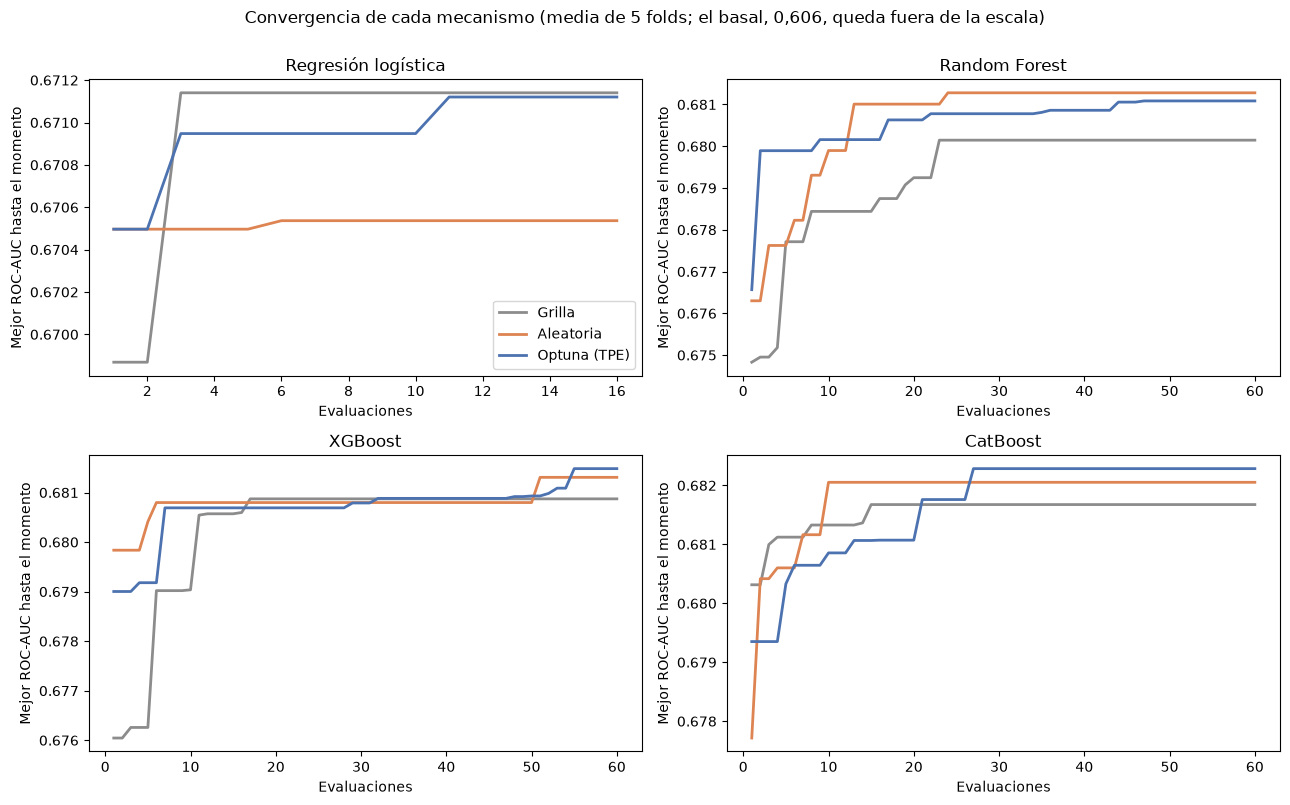

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8), sharex=False)
colores = {"Grilla": "#8C8C8C", "Aleatoria": "#DD8452", "Optuna (TPE)": "#4C72B0"}
for ax, nombre in zip(axes.flat, ALGORITMOS):
    for mec in MECANISMOS:
        g = ensayos[(ensayos["algoritmo"] == nombre) & (ensayos["mecanismo"] == mec)
                    & (ensayos["semilla"] == SEMILLAS_CARRERA[0])].sort_values("evaluacion")
        ax.plot(g["evaluacion"], np.maximum.accumulate(g["auc_media"]), label=mec, color=colores[mec], lw=2)
    ax.set_title(nombre)
    ax.set_xlabel("Evaluaciones")
    ax.set_ylabel("Mejor ROC-AUC hasta el momento")
axes[0, 0].legend()
plt.suptitle("Convergencia de cada mecanismo (media de 5 folds; el basal, 0,606, queda fuera de la escala)", y=1.0)
plt.tight_layout()
plt.show()

**Lectura del gráfico.** Las curvas suben rápido y se aplanan. Cada mecanismo llega a 0,001 de su mejor valor
entre la evaluación 1 y la 21: en la regresión logística, en las primeras 3; en XGBoost, entre la 5 y la 11;
en Random Forest, entre la 9 y la 20; y en CatBoost, entre la 3 y la 21. Después las mejoras son de milésimas.
Con 60 evaluaciones, Optuna no se despega de la búsqueda aleatoria: con pocos hiperparámetros y un óptimo en
meseta, una búsqueda simple alcanza. Es lo esperable según Bergstra y Bengio (2012), que mostraron que la búsqueda
aleatoria rinde tanto o más que la grilla cuando solo unos pocos hiperparámetros importan de verdad. La escala del eje está acotada a
propósito para ver las diferencias entre mecanismos; el basal (0,606) queda muy por debajo, y todos los
mecanismos parten muy por encima de él desde la primera evaluación.

In [9]:
filas = []
for nombre in ALGORITMOS:
    g = res_carrera.loc[nombre]
    mejor = g["mejor ROC-AUC (media 5 folds)"].idxmax()
    tope, desvio = g.loc[mejor, "mejor ROC-AUC (media 5 folds)"], g.loc[mejor, "desvío entre folds"]
    empatados = [m for m in g.index if tope - g.loc[m, "mejor ROC-AUC (media 5 folds)"] < desvio]
    ganador = min(empatados, key=lambda m: g.loc[m, "segundos totales"]) if len(empatados) > 1 else mejor
    filas.append({"algoritmo": nombre, "mecanismo con mejor puntaje": mejor,
                  "mecanismos empatados (dentro del desvío)": ", ".join(empatados),
                  "ganador elegido": ganador, "ROC-AUC del ganador": g.loc[ganador, "mejor ROC-AUC (media 5 folds)"],
                  "hiperparámetros": g.loc[ganador, "hiperparámetros"]})
ganadores = pd.DataFrame(filas).set_index("algoritmo")
ganadores.round(4)

,mecanismo con mejor puntaje,mecanismos empatados (dentro del desvío),ganador elegido,ROC-AUC del ganador,hiperparámetros
algoritmo,,,,,
Regresión logística,Grilla,"Grilla, Aleatoria, Optuna (TPE)",Aleatoria,0.6705,"{'C': 0.010051981180656781, 'l1_ratio': 1.0}"
Random Forest,Aleatoria,"Grilla, Aleatoria, Optuna (TPE)",Optuna (TPE),0.6811,"{'max_features': 0.4149670947833069, 'min_samples_leaf': 14, 'max_depth': 10}"
XGBoost,Optuna (TPE),"Grilla, Aleatoria, Optuna (TPE)",Grilla,0.6809,"{'learning_rate': 0.02, 'max_depth': 6, 'min_child_weight': 3, 'subsample': 0.8, 'colsample_bytree': 0.8, 'reg_lambd..."
CatBoost,Optuna (TPE),"Grilla, Aleatoria, Optuna (TPE)",Aleatoria,0.6821,"{'learning_rate': 0.02385264834812575, 'depth': 6, 'l2_leaf_reg': 24.64598838968805, 'random_strength': 0.9057530099..."


**Lectura de los ganadores.** En los cuatro algoritmos los tres mecanismos quedan empatados, así que, por la
regla declarada, el ganador es el más barato en tiempo: la búsqueda aleatoria para la regresión logística
(0,6705; `C` = 0,010 con penalización Lasso) y para CatBoost (0,6821), Optuna para Random Forest (0,6811;
`max_features` 0,41, `min_samples_leaf` 14, `max_depth` 10) y la grilla para XGBoost (0,6809;
`learning_rate` 0,02, `max_depth` 6, `min_child_weight` 3). Quién gana es consecuencia del empate y no dice
nada sobre el algoritmo. Mecanismos distintos encontraron hiperparámetros muy distintos con el mismo puntaje
(en XGBoost, la grilla eligió profundidad 6 y la aleatoria profundidad 8): el óptimo es una **meseta** y no un
punto único. El early stopping usó unos 150 a 240 árboles por fold con la configuración ganadora de XGBoost y
340 a 560 con la de CatBoost.

In [10]:
# Validación de los ganadores con folds de otras semillas (43 a 45): el puntaje de la carrera es optimista.
filas = []
for nombre in ALGORITMOS:
    p = ganadores.loc[nombre, "hiperparámetros"]
    por_semilla = []
    for s in SEMILLAS_CV[1:]:
        aucs, iters = evaluar_config(nombre, p, SEMILLA, semilla_cv=s)
        por_semilla.append(aucs.mean())
        registrar(fase="M5-validación", algoritmo=nombre, mecanismo=ganadores.loc[nombre, "ganador elegido"],
                  semilla=s, auc_media=float(aucs.mean()), auc_desvio=float(aucs.std(ddof=1)),
                  parametros=json.dumps(p))
    filas.append({"algoritmo": nombre, "ROC-AUC en la carrera (semilla 42)": ganadores.loc[nombre, "ROC-AUC del ganador"],
                  "ROC-AUC en folds de otras semillas (43 a 45)": float(np.mean(por_semilla)),
                  "desvío entre semillas": float(np.std(por_semilla, ddof=1))})
validacion = pd.DataFrame(filas).set_index("algoritmo")
validacion["optimismo de la carrera"] = (validacion["ROC-AUC en la carrera (semilla 42)"]
                                         - validacion["ROC-AUC en folds de otras semillas (43 a 45)"])
guardar_registro()

(ARTEFACTOS / "configuracion_m5.json").write_text(json.dumps({
    "presupuesto": PRESUPUESTO, "mecanismos": MECANISMOS, "semillas_carrera": SEMILLAS_CARRERA,
    "max_arboles": MAX_ARBOLES, "early_stopping_rounds": 50,
    "espacios": {n: {k: list(v) for k, v in e.items()} for n, e in ESPACIOS.items()},
    "ganadores": {n: {"mecanismo": ganadores.loc[n, "ganador elegido"], "hiperparametros": ganadores.loc[n, "hiperparámetros"],
                      "roc_auc_carrera": float(ganadores.loc[n, "ROC-AUC del ganador"])} for n in ALGORITMOS}},
    indent=1, default=float))
print(f"Tiempo total de M5 en esta ejecución: {(time.perf_counter() - inicio) / 60:.1f} min")
validacion.round(4)

Tiempo total de M5 en esta ejecución: 2.0 min


,ROC-AUC en la carrera (semilla 42),ROC-AUC en folds de otras semillas (43 a 45),desvío entre semillas,optimismo de la carrera
algoritmo,,,,
Regresión logística,0.6705,0.6705,0.0001,0.0000
Random Forest,0.6811,0.6811,0.0003,-0.0001
XGBoost,0.6809,0.6812,0.0010,-0.0004
CatBoost,0.6821,0.6831,0.0006,-0.0011


**Lectura de la validación con otras semillas.** Evaluados con folds de otras semillas, los ganadores rinden
prácticamente lo mismo que en la carrera: el optimismo del puntaje (la "maldición del ganador") va de 0,000 a
−0,001, es decir que incluso rinden algo mejor en los folds nuevos, y el desvío entre semillas es de 0,0001 a
0,001. Con 60 evaluaciones sobre espacios de 2 a 7 hiperparámetros y un puntaje en meseta, la elección del
mejor no infla el resultado de manera apreciable.

In [11]:
antes_despues = pd.DataFrame({
    "ROC-AUC con valores por defecto (M4)": resumen_m4["ROC-AUC validación"],
    "ROC-AUC con el ganador de la carrera": ganadores["ROC-AUC del ganador"]})
antes_despues["mejora por el ajuste"] = (antes_despues["ROC-AUC con el ganador de la carrera"]
                                         - antes_despues["ROC-AUC con valores por defecto (M4)"])
antes_despues["ROC-AUC del basal"] = auc_basal.mean()
antes_despues.round(4)

,ROC-AUC con valores por defecto (M4),ROC-AUC con el ganador de la carrera,mejora por el ajuste,ROC-AUC del basal
algoritmo,,,,
Regresión logística,0.6704,0.6705,0.0001,0.6061
Random Forest,0.6493,0.6811,0.0318,0.6061
XGBoost,0.6574,0.6809,0.0235,0.6061
CatBoost,0.6744,0.6821,0.0077,0.6061


**Lectura.** El ajuste ayuda según la familia. Random Forest sube de 0,649 a 0,681 y XGBoost de 0,657 a 0,681,
porque sus valores por defecto sobreajustaban (M4). CatBoost mejora poco, de 0,674 a 0,682, y la regresión
logística no cambia (0,6704 a 0,6705): con 18 variables y 57.000 filas casi no tiene margen de
sobreajuste. Después del ajuste, los tres ensambles quedan entre 0,681 y 0,682, unas 0,011 por encima de la
logística, y todos a unos 0,075 del basal. Si esas diferencias son reales se decide formalmente en M7.

### Estabilidad de la carrera

Como los mecanismos quedaron empatados, la carrera se repite con dos semillas más (43 y 44). Los folds son los
mismos; cambian la semilla de los mecanismos (qué combinaciones prueban la aleatoria y Optuna) y la de los
modelos. Sirve para ver si el resultado depende de la suerte de una corrida.

semilla 42  semilla 43  semilla 44   media  \
algoritmo           mecanismo                                                  
Regresión logística Grilla            0.6711      0.6711      0.6711  0.6711   
                    Aleatoria         0.6705      0.6712      0.6711  0.6710   
                    Optuna (TPE)      0.6711      0.6712      0.6711  0.6711   
Random Forest       Grilla            0.6801      0.6804      0.6803  0.6803   
                    Aleatoria         0.6813      0.6801      0.6811  0.6808   
                    Optuna (TPE)      0.6811      0.6812      0.6811  0.6811   
XGBoost             Grilla            0.6809      0.6805      0.6809  0.6807   
                    Aleatoria         0.6813      0.6810      0.6810  0.6811   
                    Optuna (TPE)      0.6815      0.6810      0.6816  0.6814   
CatBoost            Grilla            0.6817      0.6818      0.6819  0.6818   
                    Aleatoria         0.6821      0.6817      0.6816  0.6818   
                    Optuna (TPE)      0.6823      0.6817      0.6824  0.6821   

                                  desvío entre semillas  
algoritmo           mecanismo                            
Regresión logística Grilla                       0.0000  
                    Aleatoria                    0.0004  
                    Optuna (TPE)                 0.0000  
Random Forest       Grilla                       0.0001  
                    Aleatoria                    0.0006  
                    Optuna (TPE)                 0.0001  
XGBoost             Grilla                       0.0002  
                    Aleatoria                    0.0002  
                    Optuna (TPE)                 0.0003  
CatBoost            Grilla                       0.0001  
                    Aleatoria                    0.0003  
                    Optuna (TPE)                 0.0004

Mejor ROC-AUC de cada carrera (entre los tres mecanismos):


,semilla 42,semilla 43,semilla 44,rango entre semillas
algoritmo,,,,
Regresión logística,0.6711,0.6712,0.6711,0.0001
Random Forest,0.6813,0.6812,0.6811,0.0002
XGBoost,0.6815,0.6810,0.6816,0.0005
CatBoost,0.6823,0.6818,0.6824,0.0006


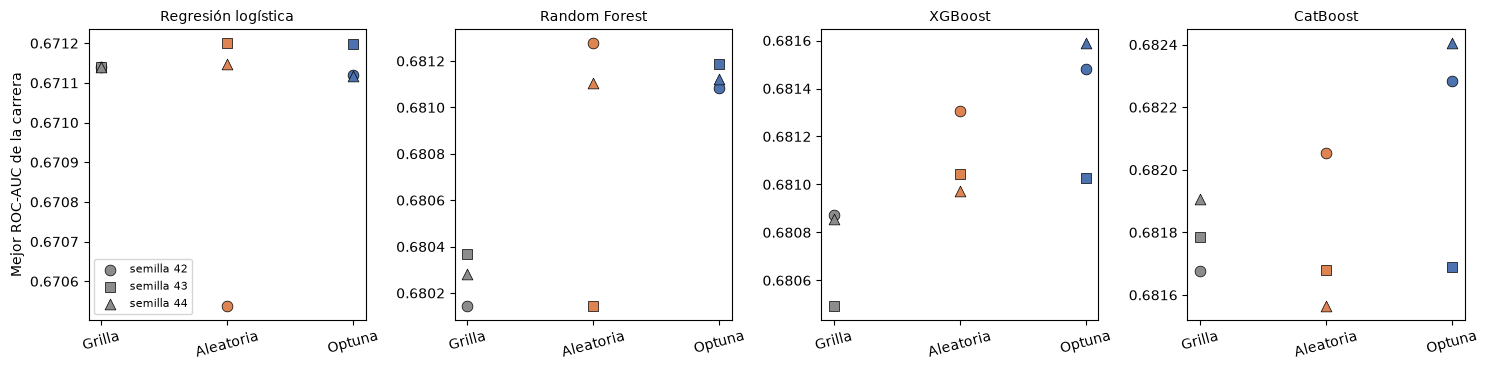

In [12]:
SEMILLAS_ESTABILIDAD = [43, 44]
ensayos_est = pd.concat([carrera(s) for s in SEMILLAS_ESTABILIDAD], ignore_index=True)
for _, r in ensayos_est.iterrows():
    registrar(fase="M5-estabilidad", algoritmo=r["algoritmo"], mecanismo=r["mecanismo"], semilla=r["semilla"],
              evaluacion=r["evaluacion"], parametros=json.dumps(r["parametros"]), auc_media=r["auc_media"],
              auc_desvio=r["auc_desvio"], segundos=r["segundos"])
todos = pd.concat([ensayos, ensayos_est], ignore_index=True)
todos.drop(columns=["parametros", "auc_folds", "arboles"]).to_csv(ARTEFACTOS / "m5_ensayos.csv", index=False)
guardar_registro()

mejor_por_semilla = todos.groupby(["algoritmo", "mecanismo", "semilla"], sort=False)["auc_media"].max().unstack("semilla")
estab = mejor_por_semilla.copy()
estab.columns = [f"semilla {c}" for c in estab.columns]
estab["media"] = mejor_por_semilla.mean(axis=1)
estab["desvío entre semillas"] = mejor_por_semilla.std(axis=1, ddof=1)
display(estab.round(4))

meseta = todos.groupby(["algoritmo", "semilla"], sort=False)["auc_media"].max().unstack("semilla")
meseta.columns = [f"semilla {c}" for c in meseta.columns]
meseta["rango entre semillas"] = meseta.max(axis=1) - meseta.min(axis=1)
print("Mejor ROC-AUC de cada carrera (entre los tres mecanismos):")
display(meseta.round(4))

fig, axes = plt.subplots(1, 4, figsize=(15, 3.8), sharey=False)
marcas = {42: "o", 43: "s", 44: "^"}
for ax, nombre in zip(axes, ALGORITMOS):
    for j, mec in enumerate(MECANISMOS):
        for s in [42, 43, 44]:
            ax.scatter(j, mejor_por_semilla.loc[(nombre, mec), s], marker=marcas[s], color=colores[mec], s=60,
                       label=f"semilla {s}" if j == 0 else None, edgecolor="black", linewidth=0.5)
    ax.set_xticks(range(3))
    ax.set_xticklabels(["Grilla", "Aleatoria", "Optuna"], rotation=15)
    ax.set_title(nombre, fontsize=10)
axes[0].set_ylabel("Mejor ROC-AUC de la carrera")
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

**Lectura de la estabilidad.** El resultado de la carrera casi no depende de la semilla: el mejor ROC-AUC de cada
algoritmo cambia entre 0,0001 y 0,0006 de una semilla a otra (regresión logística 0,6711 a 0,6712; Random
Forest 0,6811 a 0,6813; XGBoost 0,6810 a 0,6816; CatBoost 0,6817 a 0,6824), mucho menos que el desvío entre
folds (0,004 a 0,006). Con las tres semillas, Optuna queda en promedio algo por encima de los otros mecanismos
en Random Forest, XGBoost y CatBoost, pero por 0,0003 a 0,0008, una diferencia que sigue estando dentro del
ruido; en la regresión logística los tres mecanismos dan lo mismo. Por lo tanto el empate no es una casualidad de
una corrida: en este problema los tres mecanismos llegan a la misma meseta, y el desempeño de cada algoritmo
queda fijado por el algoritmo y no por cómo se buscaron sus hiperparámetros.

## 8.6 M6: Calibración y umbral

El umbral y la calibración responden a preguntas distintas. El umbral decide a quién marcar; la calibración
dice si una probabilidad de 0,3 significa que reingresa el 30 % de esos pacientes. Primero elegimos el umbral y
después, en 8.6.1, evaluamos la calibración.

**Umbral.** Recall, precisión, F1 y exactitud balanceada requieren una decisión, y el umbral se trata como un
hiperparámetro que se elige sin mirar el test. Seguimos el procedimiento de la notebook *1 - Modelos que votan* de la clase 5, donde el umbral es un
hiperparámetro más y se elige por validación cruzada: se juntan las **predicciones fuera de fold** de todo el train (cada paciente-encuentro predicho por un modelo que
no lo vio), se recorren 181 umbrales entre 0,05 y 0,95, se calcula el F1 en cada uno y se elige el que lo
maximiza. Ese umbral queda fijo y es el que se aplicará una sola vez al test en M9.

Para informar las métricas secundarias con incertidumbre, y sin que el umbral se ajuste sobre los mismos datos
que se evalúan, se usa además un **umbral anidado por fold**: en cada fold el umbral se elige con las
predicciones de los otros cuatro folds y se aplica al fold que quedó afuera. Las predicciones son las del
ganador de la carrera de M5 de cada algoritmo, sobre los folds de la semilla 42.

In [13]:
UMBRALES = np.linspace(0.05, 0.95, 181)
CONFIG_GANADORA = {n: ganadores.loc[n, "hiperparámetros"] for n in ALGORITMOS}


def prob_oof(nombre, p, semilla_cv=42, semilla_modelo=SEMILLA):
    # Probabilidad fuera de fold de cada paciente-encuentro de train, con el modelo ganador (early stopping como en M5).
    oof, arboles = np.full(len(y_ent), np.nan), []
    for k in range(N_FOLDS):
        Ztr, Zva, ytr, yva = matrices(semilla_cv, k)
        m = construir(nombre, p, semilla_modelo)
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            if nombre == "XGBoost":
                a, b = interno(semilla_cv, k)
                m.fit(Ztr[a], ytr[a], eval_set=[(Ztr[b], ytr[b])], verbose=False)
                arboles.append(m.best_iteration + 1)
                pv = m.predict_proba(Zva, iteration_range=(0, arboles[-1]))[:, 1]
            elif nombre == "CatBoost":
                a, b = interno(semilla_cv, k)
                m.fit(Ztr[a], ytr[a], eval_set=(Ztr[b], ytr[b]), use_best_model=True)
                arboles.append(m.get_best_iteration() + 1)
                pv = m.predict_proba(Zva)[:, 1]
            else:
                m.fit(Ztr, ytr)
                pv = m.predict_proba(Zva)[:, 1]
        oof[pares(semilla_cv)[k][1]] = pv
    assert not np.isnan(oof).any()
    return oof, arboles


OOF, ARBOLES = {}, {}
for nombre in ALGORITMOS:
    OOF[nombre], ARBOLES[nombre] = prob_oof(nombre, CONFIG_GANADORA[nombre])


def curva_f1(y, p):
    return np.array([f1_score(y, (p >= u).astype(int), zero_division=0) for u in UMBRALES])


ids_fold = FOLD_ID[42]
filas, curvas = [], {}
for nombre in ALGORITMOS:
    p = OOF[nombre]
    curvas[nombre] = curva_f1(y_ent, p)
    u_final = UMBRALES[int(np.argmax(curvas[nombre]))]
    por_fold = []
    for k in range(N_FOLDS):
        fuera, dentro = ids_fold != k, ids_fold == k
        u_k = UMBRALES[int(np.argmax(curva_f1(y_ent[fuera], p[fuera])))]       # umbral anidado: sin el fold k
        pred = (p[dentro] >= u_k).astype(int)
        m = metricas(y_ent[dentro], p[dentro], pred)
        por_fold.append({**m, "umbral": u_k})
        registrar(fase="M6", algoritmo=nombre, semilla=42, fold=k + 1, **m, umbral=u_k)
    d = pd.DataFrame(por_fold)
    fila = {"algoritmo": nombre, "umbral elegido (todo train)": u_final}
    for c in ["ROC-AUC", "AUC-PR", "recall", "precisión", "F1", "exactitud balanceada"]:
        fila[f"{c}"] = f"{d[c].mean():.3f} ± {d[c].std():.3f}"
    filas.append(fila)
umbrales_m6 = pd.DataFrame(filas).set_index("algoritmo")

# Basal y prevalencia: sin umbral que elegir (regla fija de M1)
fila_basal = {"umbral elegido (todo train)": "regla fija (≥ 1 internación previa)"}
fila_prev = {"umbral elegido (todo train)": "—"}
for c in ["ROC-AUC", "AUC-PR", "recall", "precisión", "F1", "exactitud balanceada"]:
    fila_basal[c] = f"{basal_folds[c].mean():.3f} ± {basal_folds[c].std():.3f}"
    fila_prev[c] = f"{prev_folds[c].mean():.3f}"
umbrales_m6.loc["Basal (regla: internaciones previas ≥ 1)"] = fila_basal
umbrales_m6.loc["Prevalencia (referencia)"] = fila_prev
guardar_registro()
(ARTEFACTOS / "umbrales.json").write_text(json.dumps(
    {n: float(UMBRALES[int(np.argmax(curvas[n]))]) for n in ALGORITMOS}, indent=1))
umbrales_m6

,umbral elegido (todo train),ROC-AUC,AUC-PR,recall,precisión,F1,exactitud balanceada
algoritmo,,,,,,,
Regresión logística,0.13,0.671 ± 0.005,0.204 ± 0.003,0.437 ± 0.012,0.208 ± 0.004,0.281 ± 0.004,0.612 ± 0.004
Random Forest,0.15,0.681 ± 0.005,0.223 ± 0.007,0.448 ± 0.035,0.212 ± 0.005,0.287 ± 0.003,0.618 ± 0.006
XGBoost,0.145,0.681 ± 0.005,0.221 ± 0.003,0.456 ± 0.020,0.210 ± 0.004,0.287 ± 0.002,0.619 ± 0.003
CatBoost,0.145,0.682 ± 0.004,0.222 ± 0.006,0.447 ± 0.029,0.211 ± 0.007,0.286 ± 0.002,0.617 ± 0.003
Basal (regla: internaciones previas ≥ 1),regla fija (≥ 1 internación previa),0.606 ± 0.004,0.161 ± 0.003,0.502 ± 0.009,0.167 ± 0.003,0.250 ± 0.004,0.592 ± 0.004
Prevalencia (referencia),—,0.500,0.113,0.000,0.000,0.000,0.500


**Lectura de la tabla.** Los umbrales elegidos con las predicciones fuera de fold quedan entre 0,13 y 0,15, muy
por debajo de 0,5, como corresponde a un problema con 11 % de positivos y modelos sin pesos de clase. Con el
umbral anidado (elegido sin el fold que se evalúa), los cuatro algoritmos logran un F1 de 0,281 a 0,287, un
recall de 0,44 a 0,46, una precisión de 0,21 y una exactitud balanceada de 0,61 a 0,62. El basal marca a todo
paciente con alguna internación previa (un 34 % del train) y obtiene F1 0,250, recall 0,50 y precisión 0,167.
Frente al basal, los algoritmos ganan unas 0,04 de precisión y unas 0,03 de F1, a costa de unas 0,05 de
recall. Entre los cuatro algoritmos las diferencias son de milésimas, menores que los desvíos entre folds. El
AUC-PR del Random Forest, XGBoost y CatBoost (0,221 a 0,223) supera al de la regresión logística (0,204) y casi
duplica la prevalencia (0,113).

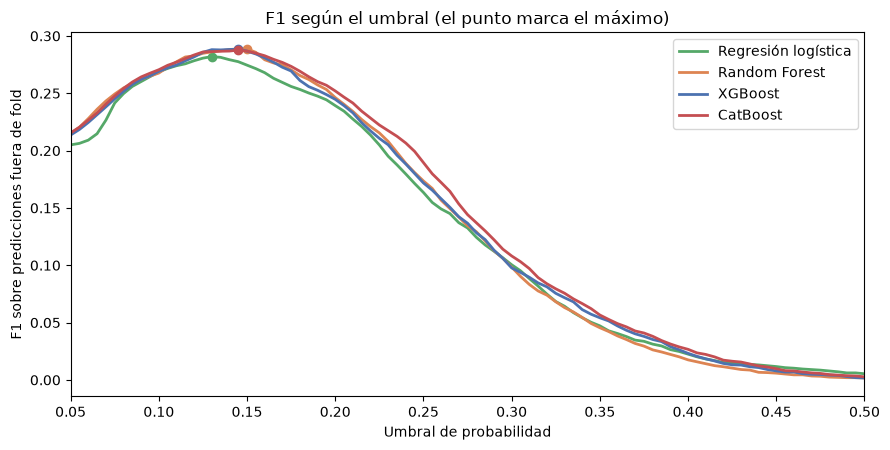

In [14]:
fig, ax = plt.subplots(figsize=(9, 4.6))
colores_alg = {"Regresión logística": "#55A868", "Random Forest": "#DD8452", "XGBoost": "#4C72B0", "CatBoost": "#C44E52"}
for nombre in ALGORITMOS:
    ax.plot(UMBRALES, curvas[nombre], label=nombre, color=colores_alg[nombre], lw=2)
    u = UMBRALES[int(np.argmax(curvas[nombre]))]
    ax.plot(u, curvas[nombre].max(), "o", color=colores_alg[nombre])
ax.set_xlim(0.05, 0.5)
ax.set_xlabel("Umbral de probabilidad")
ax.set_ylabel("F1 sobre predicciones fuera de fold")
ax.set_title("F1 según el umbral (el punto marca el máximo)")
ax.legend()
plt.tight_layout()
plt.show()

**Lectura del gráfico.** Las curvas de F1 de los cuatro algoritmos casi se superponen. El F1 sube hasta un
máximo de unos 0,28 a 0,29 entre los umbrales 0,13 y 0,15, y baja lentamente: cerca del máximo la curva es
plana, de modo que un umbral algo distinto daría resultados parecidos. Con el corte habitual de 0,5 el F1 sería
prácticamente cero, porque casi ningún paciente supera ese valor; por eso el umbral tiene que moverse.

### 8.6.1 Calibración de las probabilidades

La métrica principal del trabajo, el ROC-AUC, solo mira el orden de los pacientes, y por eso no dice nada sobre
si las probabilidades son creíbles. Como vimos en la clase 7, eso importa cuando la probabilidad se comunica a una
persona: en medicina no es lo mismo informar un riesgo de reingreso del 10 % que uno del 40 %. Nuestro problema
es exactamente ese caso, así que evaluamos la calibración siguiendo la notebook *1 - Calibracion de modelos* de
esa clase:

1. **Diagnóstico.** Curvas de calibración con 10 intervalos, acompañadas del histograma de probabilidades para no
   sacar conclusiones de intervalos con pocos pacientes, más el puntaje de Brier y el error esperado de
   calibración (ECE). El Brier se compara con el de un modelo que predice siempre la tasa base.
2. **Corrección.** Probamos los dos métodos de la clase: Platt (una regresión logística sobre la salida del
   modelo) y regresión isotónica. Con más de 5.000 observaciones, la clase recomienda probar ambos.
3. **Sin tocar datos que no corresponden.** Todo se hace sobre las predicciones fuera de fold de M6, nunca sobre
   las de entrenamiento. Además, el calibrador de cada fold se ajusta con los otros cuatro, así que tampoco se
   evalúa sobre lo mismo que se ajusta. En M9 (notebook 4) se comprueba en el test.

In [15]:
# Calibración (clase 7): diagnóstico y corrección sobre las predicciones fuera de fold de M6
from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss
from sklearn.isotonic import IsotonicRegression

y_oof = y_ent.to_numpy()
BRIER_TASA_BASE = brier_score_loss(y_oof, np.full(len(y_oof), y_oof.mean()))
CAL_METODOS = ["Platt", "Isotónica"]


def ece(y, p, n_bins=10):
    # Error esperado de calibración: distancia media a la diagonal, ponderada por el tamaño de cada intervalo.
    y, p = np.asarray(y), np.asarray(p)
    bordes = np.linspace(0, 1, n_bins + 1)
    grupo = np.clip(np.digitize(p, bordes[1:-1]), 0, n_bins - 1)
    return float(sum((grupo == b).mean() * abs(y[grupo == b].mean() - p[grupo == b].mean())
                     for b in range(n_bins) if (grupo == b).any()))


def _logit(p):
    p = np.clip(p, 1e-6, 1 - 1e-6)
    return np.log(p / (1 - p)).reshape(-1, 1)


def ajustar_calibrador(p, y, metodo):
    if metodo == "Platt":
        return LogisticRegression(C=1e6, max_iter=1000).fit(_logit(p), y)
    return IsotonicRegression(out_of_bounds="clip", y_min=0, y_max=1).fit(p, y)


def aplicar_calibrador(cal, p, metodo):
    return cal.predict_proba(_logit(p))[:, 1] if metodo == "Platt" else cal.predict(p)


def calibrar_fuera_de_fold(p, metodo):
    # El calibrador de cada fold se ajusta con las predicciones de los otros cuatro.
    salida = np.zeros_like(p)
    for tr, va in pares(42):
        salida[va] = aplicar_calibrador(ajustar_calibrador(p[tr], y_oof[tr], metodo), p[va], metodo)
    return salida


PROB_CAL = {n: {"Sin calibrar": OOF[n], **{m: calibrar_fuera_de_fold(OOF[n], m) for m in CAL_METODOS}}
            for n in ALGORITMOS}
filas = []
for n in ALGORITMOS:
    for m, p in PROB_CAL[n].items():
        filas.append({"algoritmo": n, "calibración": m, "Brier": brier_score_loss(y_oof, p), "ECE": ece(y_oof, p),
                      "ROC-AUC": roc_auc_score(y_oof, p), "probabilidad media": p.mean(),
                      "probabilidad máxima": p.max()})
tabla_cal = pd.DataFrame(filas).set_index(["algoritmo", "calibración"])

# Calibradores finales, ajustados con todas las predicciones fuera de fold: se aplican al test en M9
CALIBRADORES = {n: {m: ajustar_calibrador(OOF[n], y_oof, m) for m in CAL_METODOS} for n in ALGORITMOS}
print(f"Tasa base del train: {y_oof.mean():.4f} | Brier de predecir siempre la tasa base: {BRIER_TASA_BASE:.4f}")
tabla_cal.round(4)

Tasa base del train: 0.1127 | Brier de predecir siempre la tasa base: 0.1000


Brier     ECE  ROC-AUC  probabilidad media  \
algoritmo           calibración                                                 
Regresión logística Sin calibrar  0.0962  0.0093   0.6704              0.1127   
                    Platt         0.0962  0.0085   0.6704              0.1127   
                    Isotónica     0.0960  0.0009   0.6688              0.1126   
Random Forest       Sin calibrar  0.0952  0.0030   0.6808              0.1114   
                    Platt         0.0951  0.0022   0.6807              0.1127   
                    Isotónica     0.0952  0.0012   0.6792              0.1126   
XGBoost             Sin calibrar  0.0952  0.0044   0.6809              0.1120   
                    Platt         0.0952  0.0022   0.6809              0.1127   
                    Isotónica     0.0953  0.0008   0.6797              0.1127   
CatBoost            Sin calibrar  0.0951  0.0031   0.6820              0.1119   
                    Platt         0.0951  0.0019   0.6820              0.1127   
                    Isotónica     0.0952  0.0006   0.6800              0.1127   

                                  probabilidad máxima  
algoritmo           calibración                        
Regresión logística Sin calibrar               0.7075  
                    Platt                      0.7261  
                    Isotónica                  0.6667  
Random Forest       Sin calibrar               0.6087  
                    Platt                      0.6637  
                    Isotónica                  0.7500  
XGBoost             Sin calibrar               0.6394  
                    Platt                      0.6999  
                    Isotónica                  0.7500  
CatBoost            Sin calibrar               0.6315  
                    Platt                      0.6738  
                    Isotónica                  0.5758

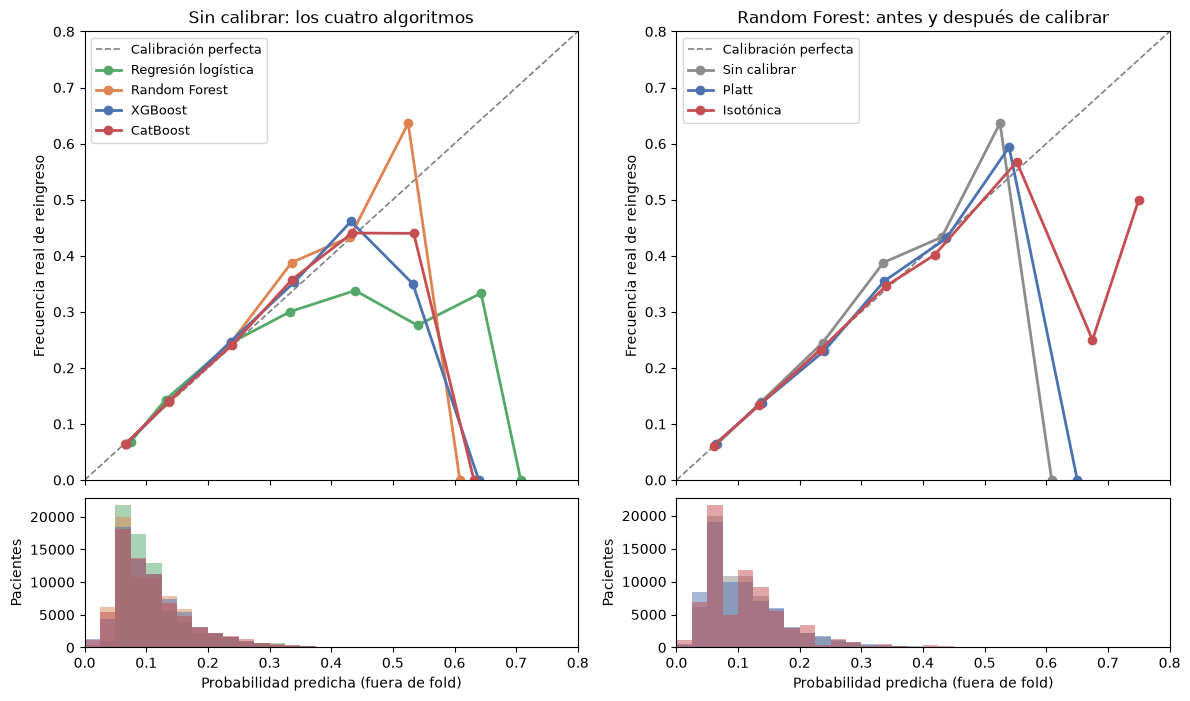

In [16]:
fig, axes = plt.subplots(2, 2, figsize=(14, 8), sharex=True, gridspec_kw={"height_ratios": [3, 1], "hspace": 0.06})
ejemplo = "Random Forest"
colores_cal = {"Sin calibrar": "#8C8C8C", "Platt": "#4C72B0", "Isotónica": "#C44E52"}
series = [({n: OOF[n] for n in ALGORITMOS}, colores_alg, "Sin calibrar: los cuatro algoritmos"),
          (PROB_CAL[ejemplo], colores_cal, f"{ejemplo}: antes y después de calibrar")]
for j, (probs, colores, titulo) in enumerate(series):
    ax, ax_h = axes[0, j], axes[1, j]
    ax.plot([0, 1], [0, 1], "--", color="gray", lw=1.2, label="Calibración perfecta")
    for nombre, p in probs.items():
        frac, media = calibration_curve(y_oof, p, n_bins=10)
        ax.plot(media, frac, "o-", lw=2, color=colores[nombre], label=nombre)
        ax_h.hist(p, bins=np.linspace(0, 1, 41), color=colores[nombre], alpha=0.5)
    ax.set_xlim(0, 0.8); ax.set_ylim(0, 0.8)
    ax.set_ylabel("Frecuencia real de reingreso")
    ax.set_title(titulo)
    ax.legend(fontsize=9)
    ax_h.set_xlabel("Probabilidad predicha (fuera de fold)")
    ax_h.set_ylabel("Pacientes")
plt.show()

**Lectura.** Los cuatro modelos ya salen bien calibrados donde están casi todos los pacientes. Hasta una
probabilidad de 0,3, que abarca a la gran mayoría de las predicciones (ver los histogramas), las curvas siguen la
diagonal: cuando el modelo dice 10 %, reingresa alrededor del 10 %. El ECE es menor a 0,01 en todos y la
probabilidad media coincide con la tasa real del train (0,113). Tiene una explicación que vimos en la clase 7:
como entrenamos sin remuestreo ni pesos de clase (sección 7.5 del notebook 1), los modelos aprenden la prevalencia
real y no la sobreestiman.

Por encima de 0,3 las curvas se separan, pero ahí quedan muy pocos pacientes y, como advirtió la clase, esos
puntos son sobre todo ruido. El caso más claro es la regresión logística, que por encima de 0,3 sobreestima el
riesgo. También coincide con la clase 7: la regresión logística está bien calibrada por construcción, pero eso se
pierde con la regularización, y la nuestra usa Lasso con C = 0,01.

Calibrar aporta poco. El Brier casi no cambia (alrededor de 0,095 en todos los casos) y el ECE baja apenas. La
regresión isotónica reduce más el ECE en todos los modelos, pero en los extremos, con pocos datos, genera saltos
bruscos (en Random Forest llega a predecir 0,75 en un tramo casi vacío) y crea empates que bajan levemente el
ROC-AUC; Platt, en cambio, conserva el orden exacto. Un detalle que vale la pena notar: el Brier de los modelos
(0,095) es apenas mejor que el de predecir siempre la tasa base (0,100), coherente con una discriminación
modesta. La conclusión es que las probabilidades de nuestros modelos ya pueden leerse como riesgos aproximados.
Para el test (M9) usamos, en cada modelo, el método con menor ECE fuera de fold.

---
## Cierre del notebook 3

Cada algoritmo queda con su configuración ganadora, su umbral de decisión y su calibrador, elegidos solo con el
train. El
notebook 4 los compara entre sí y con el basal, analiza qué aprendieron y los evalúa por única vez en el test.

---
### Estado de la sesión para el notebook siguiente

Se guarda el estado completo de la sesión (datos, variables y funciones definidas hasta acá) para que el
notebook siguiente continúe exactamente desde este punto, sin repetir los cálculos. El archivo queda en
`artefactos_ml/` y no se sube al repositorio por su tamaño.

In [17]:
import dill
from pathlib import Path
Path("artefactos_ml").mkdir(exist_ok=True)
dill.dump_session("artefactos_ml/estado_03.pkl")
dill.extend(False)            # deja el pickle estándar como estaba
print("Estado guardado en artefactos_ml/estado_03.pkl")

Estado guardado en artefactos_ml/estado_03.pkl
